# Curvilinear grids: waves under topography

This tutorial simulates an acoustic shot over a hill, with a free surface that follows the topography. On a `Grid` the nodes form a box, so a curved surface can only be approximated by a staircase of grid cells, which introduces errors in the waves that reflect off it. A `CurvilinearGrid` removes the staircase: it bends the grid so that the surface is a grid line.

Throughout the notebook, $x$ and $z$ are the physical coordinates in metres, with $z$ the depth, positive down as everywhere in Devito. A `CurvilinearGrid` is still indexed like a `Grid`, by integer nodes along each axis; the uniformly spaced coordinates of those nodes are the computational coordinates $\xi$ (lateral) and $\eta$ (vertical), indexed by the grid Dimensions. The grid is defined by a map that gives the physical position $(x, z)$ of each computational node $(\xi, \eta)$. Note that in 2D Devito names the vertical Dimension `y`, so below `y` is the vertical grid Dimension and `u.dy` the vertical derivative.

We build the hill, look at the grid, see how derivatives, sources and models work on it, impose the free surface, and run the simulation. A final section checks the accuracy against an analytic solution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from devito import (CurvilinearGrid, CurvilinearMap, Eq, Function, Grid, Operator,
                    SparseTimeFunction, TerrainFollowing, TimeFunction)

## The hill and the terrain-following map

The topography is a hill 150 m high, centred at $x = 1.5$ km on a 3 km line. It is given, as topography usually is, by its elevation above a datum, positive up.

In [2]:
def elevation(x):
    return 150.*np.exp(-((x - 1500.)/400.)**2)

The map `TerrainFollowing` keeps the lateral coordinate, $x = \xi$, and stretches each column linearly between the surface at depth $s(x)$, at computational depth $\eta = 0$, and the flat bottom of the grid, at $\eta = z = b$:

$$z(\xi, \eta) = s(\xi) + \eta\,\frac{b - s(\xi)}{b}.$$

The row at $\eta = 0$ is the surface and the last row is the bottom. Rows above the surface, at negative $\eta$, are placed by the same map: the free surface below mirrors the wavefield into them. Since depths are positive down, the surface depth is the negative of the elevation, `surface=-elevation`. The surface can be a function of $x$, as here, or an array with one value per lateral node.

The grid has 301 by 151 nodes from the surface to the bottom, over 3000 m by 1500 m, so its spacing is 10 m and the flat bottom is at $z = 1500$ m, and 4 more rows above the surface, which its vertical `origin` of -40 m places. Apart from `mapping`, the arguments are those of a `Grid`.

In [3]:
surface_row = 4  # rows above the surface, for the free surface
mapping = TerrainFollowing(surface=lambda x: -elevation(x))
grid = CurvilinearGrid(shape=(301, 151 + surface_row),
                       extent=(3000., 1500. + 10.*surface_row),
                       origin=(0., -10.*surface_row), mapping=mapping)
x, y = grid.dimensions

print(f'Dimensions {grid.dimensions}, spacing {float(grid.spacing[0]):.0f} m')

Dimensions (x, y), spacing 10 m


`grid.coordinates` holds the physical coordinates $x$ and $z$ of every node, as two `Function`s. Plotting every fifth grid line in physical space shows the columns stretched between the hill and the flat bottom: the rows follow the hill near the surface and flatten with depth.

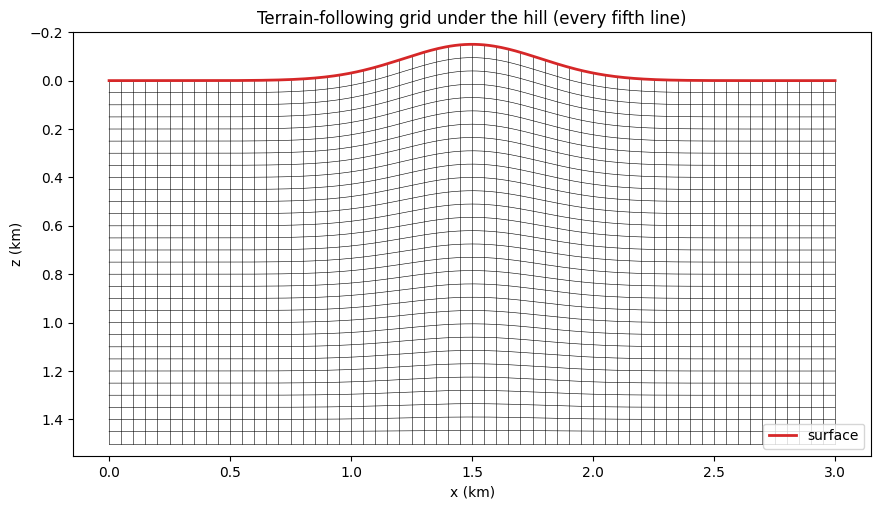

In [4]:
# NBVAL_IGNORE_OUTPUT
# From the surface down
below = (slice(None), slice(surface_row, None))
x_coord, z_coord = (c.data[below]/1000 for c in grid.coordinates)


def plot_grid_lines(ax, step=5):
    ax.plot(x_coord[::step, :].T, z_coord[::step, :].T, 'k', lw=.4)
    ax.plot(x_coord[:, ::step], z_coord[:, ::step], 'k', lw=.4)


fig, ax = plt.subplots(figsize=(12, 5.5))
plot_grid_lines(ax)
ax.plot(x_coord[:, 0], z_coord[:, 0], 'C3', lw=2, label='surface')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.set_ylim(1.55, -.2)
ax.set_aspect('equal')
ax.legend(loc='lower right')
ax.set_title('Terrain-following grid under the hill (every fifth line)')
plt.show()

## What the map changes: metrics and Jacobian

The simulation needs the Laplacian of the wavefield with respect to the physical coordinates, but the finite differences are taken along the grid, with respect to $\xi$ and $\eta$. The chain rule connects the two through the metric terms, the derivatives of the computational coordinates with respect to the physical ones. For this map $\partial\xi/\partial x = 1$ and $\partial\xi/\partial z = 0$, and the two terms that vary in space are $\partial\eta/\partial x$, which measures the slope of the rows, and $\partial\eta/\partial z$, the vertical stretching. The grid also provides the Jacobian $J$, the area of a physical cell divided by the area of a computational cell, which sources need below.

`grid.metrics` is a dictionary keyed by (physical Dimension, computational Dimension). Entries that vary are `Function`s named after the computational coordinate and the physical axis, so `eta_x` is $\partial\eta/\partial x$; constant entries stay plain numbers.

In [5]:
grid.metrics

{(x, x): 1, (y, x): 0, (x, y): eta_x(x, y), (y, y): eta_y(x, y)}

The slope term is large on the flanks of the hill and fades with depth, while $J$ is above one under the hill, where each column spans a longer physical height.

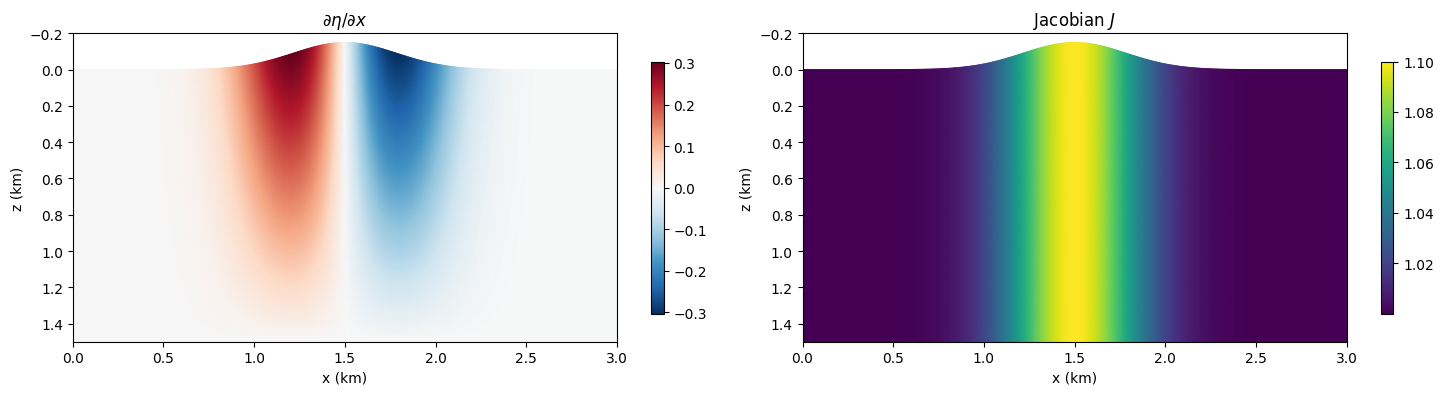

In [6]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
panels = [(grid.metrics[(x, y)].data[below], r'$\partial\eta/\partial x$', 'RdBu_r'),
          (grid.jacobian.data[below], 'Jacobian $J$', 'viridis')]
for ax, (values, title, cmap) in zip(axes, panels, strict=True):
    image = ax.pcolormesh(x_coord, z_coord, values, cmap=cmap, shading='gouraud')
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_xlabel('x (km)')
    ax.set_ylabel('z (km)')
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=.6)
plt.tight_layout()
plt.show()

## Derivatives on the hill

On a `CurvilinearGrid`, `u.dx` is the derivative with respect to the physical $x$. Devito applies the chain rule when the derivative is evaluated,

$$\frac{\partial u}{\partial x} = \frac{\partial u}{\partial \xi} + \frac{\partial \eta}{\partial x}\frac{\partial u}{\partial \eta},$$

which is visible in the stencil of a low-order derivative: a difference along the grid $x$ axis, plus a difference along the grid $y$ axis multiplied by the metric `eta_x`.

In [7]:
u = Function(name='u', grid=grid, space_order=2)
u.dx.evaluate

-u(x, y)/h_x + u(x + h_x, y)/h_x + (-0.5*u(x, y - h_y)/h_y + 0.5*u(x, y + h_y)/h_y)*eta_x(x, y)

The derivative along the grid axis itself, ignoring the map, is written `u.dx(computational=True)`.

A quick way to see that the physical derivatives are right is to differentiate the physical depth $z$ itself: $\partial z/\partial x$ must vanish and $\partial z/\partial z$ must be one everywhere, even though $z$ varies along the grid rows.

In [8]:
# NBVAL_IGNORE_OUTPUT
depth = Function(name='depth', grid=grid, space_order=8)
dzdx = Function(name='dzdx', grid=grid, space_order=8)
dzdz = Function(name='dzdz', grid=grid, space_order=8)
depth.data_with_halo[:] = grid.coordinates[1].data_with_halo

summary = Operator([Eq(dzdx, depth.dx), Eq(dzdz, depth.dy)]).apply()

NUMA domain count autodetection failed, assuming 1


Operator `Kernel` ran in 0.01 s


In [9]:
interior = (slice(4, -4), slice(4, -4))
print(f'max |dz/dx|     = {np.abs(dzdx.data[interior]).max():.1e}')
print(f'max |dz/dz - 1| = {np.abs(dzdz.data[interior] - 1).max():.1e}')

max |dz/dx|     = 1.1e-05
max |dz/dz - 1| = 1.0e-05


The wave equation below uses `u.laplace`. Second derivatives are not two first derivatives: Devito expands them with the products of metrics, the mixed grid derivative and the derivatives of the metrics (`grid.metric_derivatives`), so that over a flat surface they are exactly the stencils of a `Grid`. Nested expressions such as `(b*u.dx).dx` for a variable density work the same way, with the outer derivative taken in conservation form, $\partial_x f = \frac{1}{J}\sum_j \partial_{\xi_j}(J\,\partial\xi_j/\partial x\,f)$, so that, as on a `Grid`, the operator is symmetric (in the inner product weighted by $J$) and the propagation self-adjoint. Transposes `.T` for adjoint modelling and staggered or rotated derivatives work too; the `Derivative` and `CurvilinearGrid` docstrings give the details. The one limit to keep in mind is that the metric `Function`s are built with the `space_order` of the grid (8 by default), which must be at least the space order of the wavefield.

## The velocity model

Velocity models are usually given on a Cartesian grid. Here the model goes from 1500 m/s above a dipping interface, at a depth of 500 m under the hill, to 2500 m/s below it. It is defined on a `Grid` that extends from 300 m above the datum to the bottom, so that it covers the hill. The interface is smoothed over a few tens of metres: a sharp step in velocity would scatter grid-scale artefacts into the wavefield, on any grid.

In [10]:
model_grid = Grid(shape=(301, 181), extent=(3000., 1800.), origin=(0., -300.))
x_model = np.linspace(0., 3000., 301)[:, None]
z_model = np.linspace(-300., 1500., 181)[None, :]
cartesian_velocity = Function(name='cartesian_velocity', grid=model_grid)
interface_depth = 500. + .1*(x_model - 1500.)
cartesian_velocity.data[:] = 2000. + 500.*np.tanh((z_model - interface_depth)/30.)

`grid.resample(f, cartesian)` sets a `Function` on the curvilinear grid to the Cartesian `Function` interpolated at the physical position of each node, which for this map is an interpolation along each column. `grid.resample(f, cartesian, transpose=True)` applies the exact transpose, which is what brings a gradient computed on the curvilinear grid back to the Cartesian model in an inversion.

In [11]:
velocity = Function(name='velocity', grid=grid, space_order=8)
grid.resample(velocity, cartesian_velocity)
print(f'velocity between {velocity.data.min():.0f} and {velocity.data.max():.0f} m/s')

velocity between 1500 and 2500 m/s


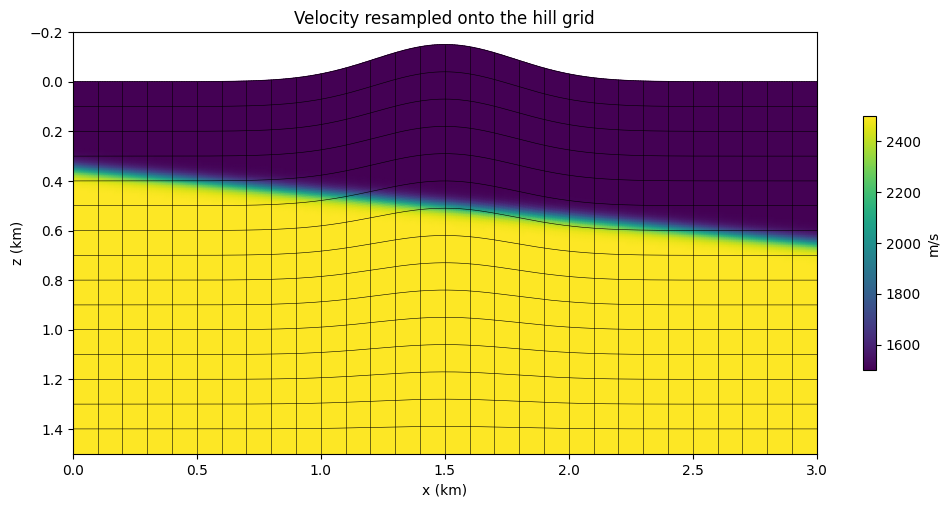

In [12]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 5.5))
image = ax.pcolormesh(x_coord, z_coord, velocity.data[below], cmap='viridis',
                      shading='gouraud')
plot_grid_lines(ax, step=10)
ax.set_ylim(1.5, -.2)
ax.set_aspect('equal')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.set_title('Velocity resampled onto the hill grid')
fig.colorbar(image, ax=ax, shrink=.6, label='m/s')
plt.show()

## Source and receivers

The coordinates of sparse functions on a `CurvilinearGrid` are physical, so the source and the receivers are placed exactly as on a `Grid`: the source 20 m below the top of the hill, and a line of 201 receivers 10 m below the surface from $x = 0.5$ km to $2.5$ km. Devito maps them onto the grid with the inverse of the map every time an `Operator` runs, so they can be moved between runs.

In [13]:
f0, t0, tn = 10., .12, 1.2  # peak frequency (Hz), wavelet delay and duration (s)
dt = .1*grid.min_spacing/velocity.data.max()
nt = int(np.ceil(tn/dt)) + 1
time_values = np.arange(nt)*dt


def ricker(t):
    a = (np.pi*f0*(t - t0))**2
    return (1 - 2*a)*np.exp(-a)


source_position = np.array([[1500., -elevation(1500.) + 20.]])
receiver_x = np.linspace(500., 2500., 201)
receiver_positions = np.stack([receiver_x, -elevation(receiver_x) + 10.], axis=1)

src = SparseTimeFunction(name='src', grid=grid, npoint=1, nt=nt,
                         coordinates=source_position)
src.data[:, 0] = ricker(time_values)
rec = SparseTimeFunction(name='rec', grid=grid, npoint=201, nt=nt,
                         coordinates=receiver_positions)
print(f'{nt} time steps of {1000*dt:.3f} ms')

3002 time steps of 0.400 ms


The time step uses `grid.min_spacing`, the smallest physical distance between neighbouring nodes, in place of the grid spacing: $\Delta t = 0.1\,h_{min}/v_{max}$, small compared with the stability limit, for the accuracy discussed in the last section.

Interpolating the wavefield at the receivers works as on a `Grid`. Injecting the source divides by the Jacobian $J$ at the nodes it is spread over, so that the injected source is a point source in physical space whatever the stretching of the cells around it.

## The free surface

The surface is a row of the grid, where the pressure must vanish. On a `Grid` this is usually done with an odd mirror: the rows above the surface are set to minus the rows below it, $u(-k) = -u(k)$. Under a slope the grid columns are not normal to the surface, and that mirror is only second-order accurate. `grid.free_surface(u.forward)` instead sets each node of the rows above the surface to minus the wavefield at its mirror image through the surface, interpolated from the nodes below; over a flat surface this is the usual odd mirror. It returns a list of equations, to be applied after each update of `u`, which write the surface row and the rows above it only.

In [14]:
u = TimeFunction(name='u', grid=grid, space_order=8, time_order=2)
m = Function(name='m', grid=grid, space_order=8)
m.data[:] = 1/velocity.data**2

surface = grid.free_surface(u.forward)
print(f'{len(surface)} equations for the surface row and the {surface_row} rows above it')

9 equations for the surface row and the 4 rows above it


## The simulation

The acoustic wave equation $m\,\partial_t^2 u - \Delta u = s$, with $m = 1/v^2$, is written exactly as it would be on a `Grid`, and the free surface equations follow the update.

In [15]:
update = Eq(u.forward, 2*u - u.backward + dt**2*u.laplace/m)
op = Operator([update] + surface +
              src.inject(field=u.forward, expr=src*dt**2/m) +
              rec.interpolate(expr=u))

We run the operator in three segments to keep a snapshot of the wavefield at 0.3 s, 0.55 s and 0.8 s.

In [16]:
# NBVAL_IGNORE_OUTPUT
snapshots = []
start = 0
for snapshot_time in [.3, .55, .8]:
    step = int(snapshot_time/dt)
    summary = op.apply(dt=dt, time_m=start, time_M=step)
    snapshots.append((snapshot_time, u.data[(step + 1) % 3].copy()))
    start = step + 1
summary = op.apply(dt=dt, time_m=start, time_M=nt - 2)

Operator `Kernel` ran in 9.37 s


Operator `Kernel` ran in 7.84 s


Operator `Kernel` ran in 7.82 s


Operator `Kernel` ran in 12.43 s


Drawn at the physical position of the nodes, the snapshots show the direct wave, its reflection off the hill with the polarity flip of a free surface, and the reflection off the dipping interface (dashed).

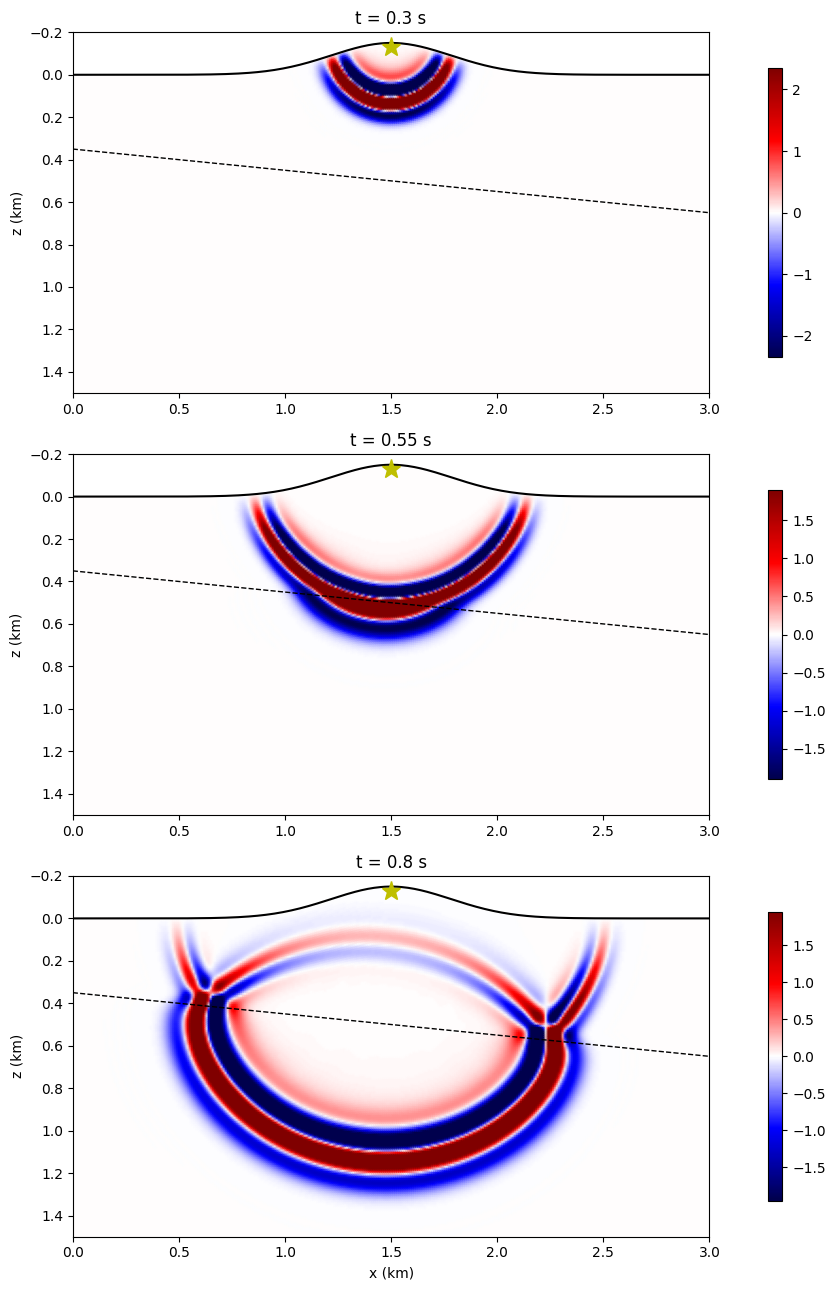

In [17]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(3, 1, figsize=(12, 13))
interface = 500. + .1*(np.linspace(0., 3000., 301) - 1500.)
for ax, (snapshot_time, snapshot) in zip(axes, snapshots, strict=True):
    clip = .3*np.abs(snapshot[below]).max()
    image = ax.pcolormesh(x_coord, z_coord, snapshot[below], cmap='seismic', vmin=-clip,
                          vmax=clip, shading='gouraud')
    ax.plot(x_coord[:, 0], z_coord[:, 0], 'k', lw=1.5)
    ax.plot(np.linspace(0., 3., 301), interface/1000, 'k--', lw=1)
    ax.plot(*(source_position/1000).T, 'y*', ms=14)
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_ylabel('z (km)')
    ax.set_title(f't = {snapshot_time} s')
    fig.colorbar(image, ax=ax, shrink=.8)
axes[-1].set_xlabel('x (km)')
plt.tight_layout()
plt.show()

The shot record shows the same events at the receivers. The receivers are only 10 m below the free surface, where the pressure is close to zero, so the direct wave is strong only next to the source; the reflection off the interface arrives between 0.9 s and 1.2 s, its shape bent by the hill. The grid has no absorbing boundary, so the record stops at 1.2 s, before the reflections off the sides and the bottom of the grid arrive.

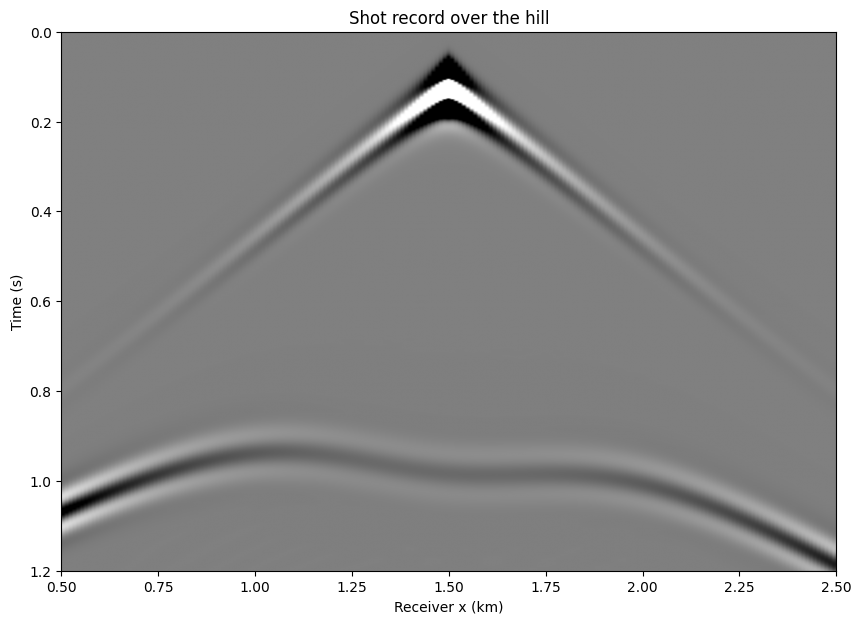

In [18]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(10, 7))
clip = .05*np.abs(rec.data).max()
ax.imshow(rec.data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip,
          extent=[receiver_x[0]/1000, receiver_x[-1]/1000, tn, 0])
ax.set_xlabel('Receiver x (km)')
ax.set_ylabel('Time (s)')
ax.set_title('Shot record over the hill')
plt.show()

## How accurate is it? A tilted plane

The hill has no analytic solution, so we check the accuracy on the simplest topography that has one: a plane surface. Over a homogeneous half-space bounded by a planar free surface, the wavefield is the field of the source minus the field of its mirror image across the plane (the image source). We take a plane dipping at 0.1 from $z = 0$ at $x = 0$, over a medium at 1500 m/s, on a grid of the same size, spacing and time-step rule as the hill.

In 2D, the free-space solution of $m\,\partial_t^2 u - \Delta u = A\,s(t)\,\delta(\mathbf{x} - \mathbf{x}_s)$ at a distance $r$ from the source, with $c$ the velocity and $\tau_0 = r/c$, is

$$u(r, t) = \frac{A}{2\pi}\int_0^{\cosh^{-1}(t/\tau_0)} s(t - \tau_0\cosh\theta)\,d\theta \quad\text{for } t > \tau_0,$$

and zero before. The source `src` injected with weight `dt**2/m` has amplitude $A = h_\xi h_\eta$, the area of a computational cell, with $h_\xi$ and $h_\eta$ the computational grid spacings (10 m by 10 m here).

In [19]:
def free_space(r, t, amplitude, c=1500.):
    field = np.zeros((len(t), len(r)))
    unit = np.linspace(0, 1, 801)
    for j, tau0 in enumerate(r/c):
        valid = t > tau0
        theta = np.arccosh(t[valid]/tau0)[:, None]*unit[None, :]
        field[valid, j] = np.trapezoid(ricker(t[valid, None] - tau0*np.cosh(theta)),
                                       theta, axis=1)
    return amplitude*field/(2*np.pi)

The function below runs the experiment on a plane with a given map and grid spacing, with either the free surface of the grid or the column mirror $u(-k) = -u(k)$, and returns the relative misfit of the receiver data to the image-source solution. By default the time step follows the same rule as for the hill, $\Delta t = 0.1\,h_{min}/v$. The source and the receivers are placed on grid nodes, using `grid.to_physical`, so that the comparison measures the propagation and the free surface rather than the interpolation of the sources and receivers.

In [20]:
slope = .1


def plane_misfit(mapping, spacing, mirror='image', dt=None):
    plane = CurvilinearGrid(shape=(int(3000/spacing) + 1, int(1500/spacing) + 5),
                            extent=(3000., 1500. + 4*spacing), origin=(0., -4*spacing),
                            mapping=mapping)
    xp, yp = plane.dimensions
    dt = dt or .1*plane.min_spacing/1500.
    nt = int(np.ceil(tn/dt)) + 1
    time_values = np.arange(nt)*dt

    source = plane.to_physical([[1500., 200.]])
    receivers = plane.to_physical(np.stack([np.linspace(1000., 2000., 101),
                                            np.full(101, 100.)], axis=1))
    src = SparseTimeFunction(name='src', grid=plane, npoint=1, nt=nt,
                             coordinates=source)
    src.data[:, 0] = ricker(time_values)
    rec = SparseTimeFunction(name='rec', grid=plane, npoint=101, nt=nt,
                             coordinates=receivers)

    u = TimeFunction(name='u', grid=plane, space_order=8, time_order=2)
    if mirror == 'image':
        surface = plane.free_surface(u.forward)
    else:
        t = plane.stepping_dim
        surface = [Eq(u[t+1, xp, 4], 0)]
        surface += [Eq(u[t+1, xp, 4 - k], -u[t+1, xp, 4 + k]) for k in range(1, 5)]
    update = Eq(u.forward, 2*u - u.backward + dt**2*1500.**2*u.laplace)
    Operator([update] + surface + src.inject(u.forward, src*dt**2*1500.**2) +
             rec.interpolate(u)).apply(dt=dt, time_M=nt - 2)

    normal = np.array([slope, -1.])
    image = source[0] - 2*(normal @ source[0])/(normal @ normal)*normal
    amplitude = np.prod(np.array(plane.spacing, dtype=np.float64))
    analytic = (
        free_space(np.linalg.norm(receivers - source, axis=1), time_values, amplitude) -
        free_space(np.linalg.norm(receivers - image, axis=1), time_values, amplitude)
    )
    misfit = np.linalg.norm(rec.data - analytic)/np.linalg.norm(analytic)
    return misfit, time_values, rec.data, analytic

At the 10 m spacing of the hill, with the plane as a `TerrainFollowing` surface:

In [21]:
# NBVAL_IGNORE_OUTPUT
plane_mapping = TerrainFollowing(surface=lambda x: slope*x)
misfit, plane_time, plane_data, plane_analytic = plane_misfit(plane_mapping, 10.)
print(f'relative misfit to the image-source solution: {misfit:.1e}')

Operator `Kernel` ran in 27.81 s


relative misfit to the image-source solution: 9.4e-04


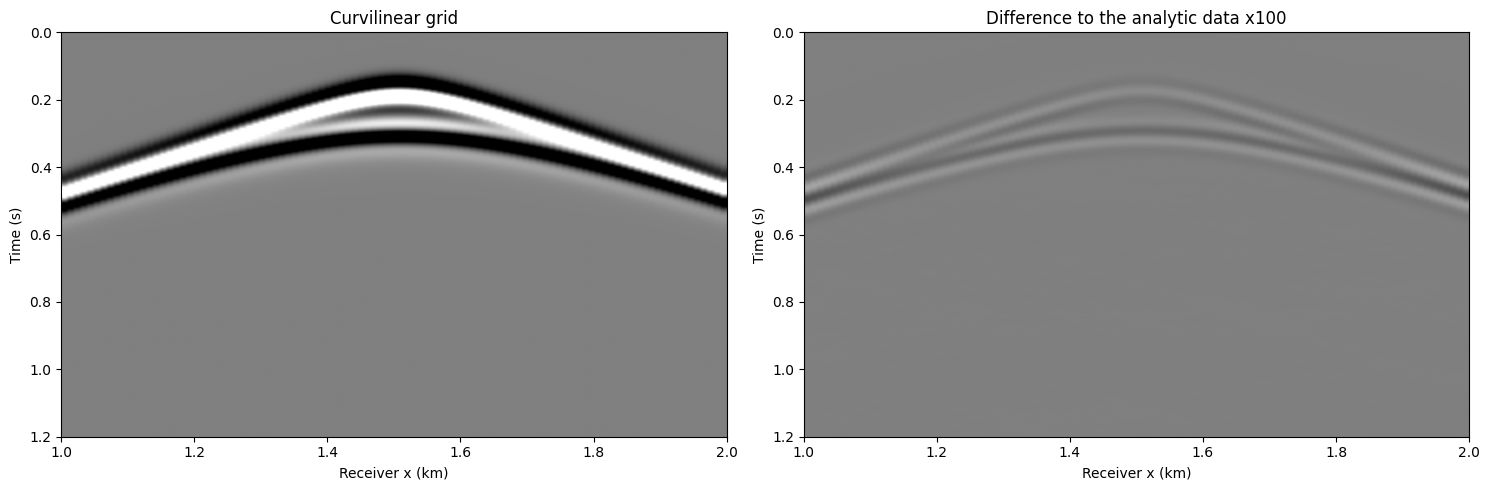

In [22]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
clip = np.abs(plane_analytic).max()/3
extent = [1., 2., tn, 0]
for ax, data, title in zip(axes, [plane_data, 100*(plane_data - plane_analytic)],
                           ['Curvilinear grid', 'Difference to the analytic data x100'],
                           strict=True):
    ax.imshow(data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip, extent=extent)
    ax.set_xlabel('Receiver x (km)')
    ax.set_ylabel('Time (s)')
    ax.set_title(title)
plt.tight_layout()
plt.show()

The difference, magnified a hundred times, is of the order of a thousandth of the data. Repeating the run at 20 m and 5 m spacing, with the free surface of the grid and with the column mirror, shows how the misfit decreases with the grid spacing $h$ (this takes about a minute).

In [23]:
# NBVAL_IGNORE_OUTPUT
spacings = [20., 10., 5.]
misfits = {mirror: [plane_misfit(plane_mapping, h, mirror)[0] for h in spacings]
           for mirror in ['image', 'column']}
for mirror, values in misfits.items():
    orders = np.log2(np.array(values[:-1])/np.array(values[1:]))
    print(f'{mirror:6s} mirror: misfits {np.round(values, 5)}, orders {orders.round(1)}')

Operator `Kernel` ran in 6.99 s


Operator `Kernel` ran in 27.77 s


Operator `Kernel` ran in 111.04 s


Operator `Kernel` ran in 0.05 s


Operator `Kernel` ran in 0.18 s


Operator `Kernel` ran in 0.93 s


image  mirror: misfits [0.04378 0.00094 0.00027], orders [5.5 1.8]
column mirror: misfits [0.04399 0.00163 0.00043], orders [4.8 1.9]


In [24]:
assert misfits['image'][1] < 2e-3
assert misfits['column'][1] > misfits['image'][1]

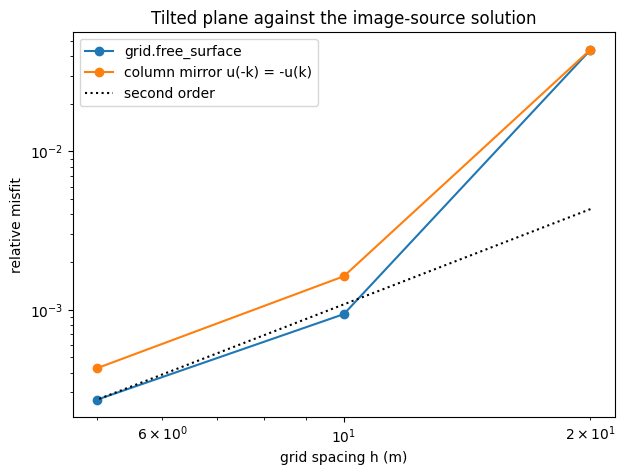

In [25]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(7, 5))
labels = {'image': 'grid.free_surface', 'column': 'column mirror u(-k) = -u(k)'}
for mirror, values in misfits.items():
    ax.loglog(spacings, values, 'o-', label=labels[mirror])
ax.loglog(spacings, misfits['image'][-1]*(np.array(spacings)/5.)**2, 'k:',
          label='second order')
ax.set_xlabel('grid spacing h (m)')
ax.set_ylabel('relative misfit')
ax.set_title('Tilted plane against the image-source solution')
ax.legend()
plt.show()

At 20 m the grid has only about three points per shortest wavelength and both runs are poor. From 10 m down, the misfit decreases at close to second order, the order of the time stepping, and the free surface of the grid has about 40 percent less misfit than the column mirror. At the 10 m spacing and time-step rule used for the hill, the data match the analytic solution to about $10^{-3}$. This bounds the error of the propagation and of the free surface over a slope; over the curved top of the hill the image is taken through the plane tangent to the surface, which this test does not measure.

### The same plane with a custom map

`TerrainFollowing` covers topography, but other geometries need other maps. A map is a subclass of `CurvilinearMap` with two methods: `forward`, the physical coordinates of computational points (it must also be smooth past the edges of the grid, where it places the halo nodes), and `inverse`, the computational coordinates of physical points, used to place sparse functions and by the free surface. The metric terms are then computed by finite differences of `forward` (see the `CurvilinearMap` docstring for the optional methods). As an example, the plane can also be built by shearing the grid, shifting each column down by `slope*x` instead of stretching it:

In [26]:
class Shear(CurvilinearMap):
    # x = xi, z = eta + slope*xi

    def __init__(self, slope):
        self.slope = slope

    def forward(self, grid, computational):
        xi, eta = computational
        return xi, eta + self.slope*xi

    def inverse(self, grid, points):
        return np.stack([points[:, 0], points[:, 1] - self.slope*points[:, 0]],
                        axis=1)

In [27]:
# NBVAL_IGNORE_OUTPUT
shear_misfit = plane_misfit(Shear(slope), 10.)[0]
print(f'sheared plane: relative misfit {shear_misfit:.1e}')

Operator `Kernel` ran in 22.42 s


sheared plane: relative misfit 1.5e-03


In [28]:
assert shear_misfit < 2e-3

The sheared plane is less accurate than the stretched one above. Its cells are not compressed under the plane, so its smallest cell is 10 m instead of 8 m and the time-step rule gives it a larger time step. With the same, smaller time step of 0.2 ms, the two maps agree, and the misfit drops further, which confirms that at the default time step the remaining error is mostly the time stepping.

In [29]:
# NBVAL_IGNORE_OUTPUT
maps = {'stretched': plane_mapping, 'sheared': Shear(slope)}
same_step = {name: plane_misfit(mapping, 10., dt=2e-4)[0]
             for name, mapping in maps.items()}
for name, value in same_step.items():
    print(f'{name} plane, dt = 0.2 ms: relative misfit {value:.1e}')

Operator `Kernel` ran in 74.01 s


Operator `Kernel` ran in 74.41 s


stretched plane, dt = 0.2 ms: relative misfit 1.4e-04
sheared plane, dt = 0.2 ms: relative misfit 1.4e-04


In [30]:
assert np.isclose(same_step['stretched'], same_step['sheared'], rtol=.1)
assert same_step['stretched'] < misfit

## Going further

Everything in this notebook runs unchanged with MPI (`DEVITO_MPI=1 mpirun -n 4 python ...`): each rank builds the coordinates and metrics of its own nodes, sparse functions are mapped onto the grid before being distributed, and the free surface equations only run on the ranks that hold the surface. The same grid works in 3D, with a surface $s(x, y)$ and Dimensions `x`, `y`, `z`.

The docstrings of `CurvilinearGrid`, `TerrainFollowing`, `CurvilinearMap`, `CurvilinearGrid.free_surface`, `CurvilinearGrid.resample` and `Derivative` (its `computational` argument) describe every option. In particular, adjoint modelling uses `.T` of the physical derivatives, which are exact discrete transposes, and injection is the transpose of interpolation in the inner product weighted by $J$.